In [5]:
import pandas as pd
import os
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import seaborn as sns

# Load Iris dataset
iris = load_iris(as_frame=True)

# Convert into DataFrame
df = iris.data
df["species"] = iris.target.map(
    dict(enumerate(iris.target_names))
)

# Create dataset folder
os.makedirs("dataset", exist_ok=True)

# Save as CSV
df.to_csv("dataset/iris.csv", index=False)

print("Iris dataset saved successfully!")

Iris dataset saved successfully!


In [4]:
data = pd.read_csv("dataset/iris.csv")

print(data.head())
print("Shape:", data.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
Shape: (150, 5)


In [6]:
print(data.columns)

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [8]:
data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [9]:
print("Duplicates:", data.duplicated().sum())

Duplicates: 1


In [10]:
print(data["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


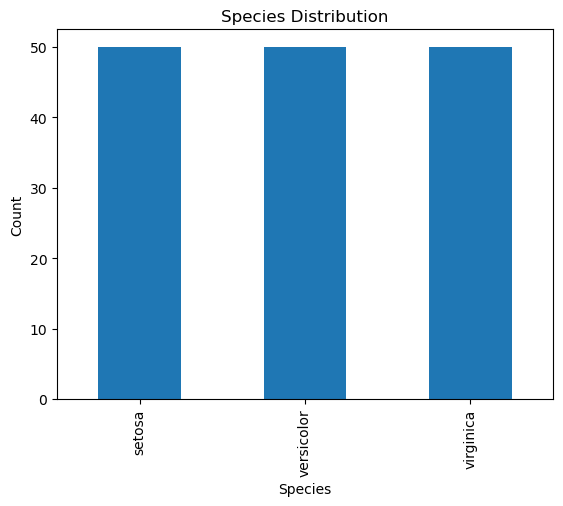

In [11]:
data["species"].value_counts().plot(kind="bar")

plt.title("Species Distribution")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

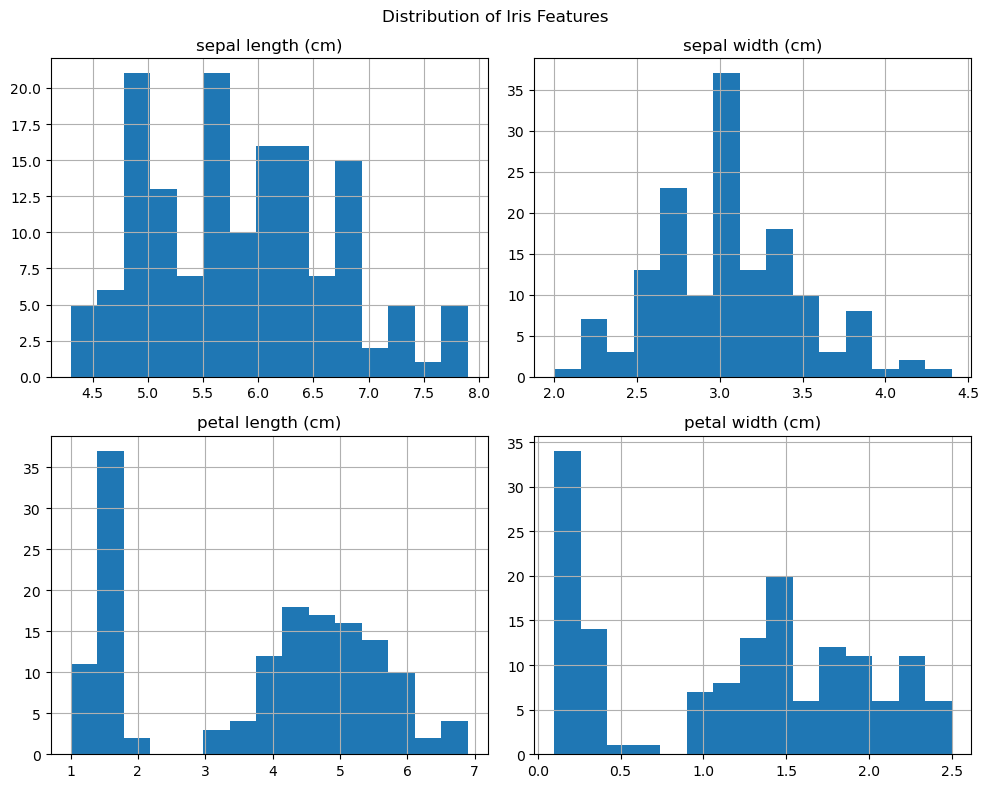

In [12]:
data.hist(figsize=(10, 8), bins=15)

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

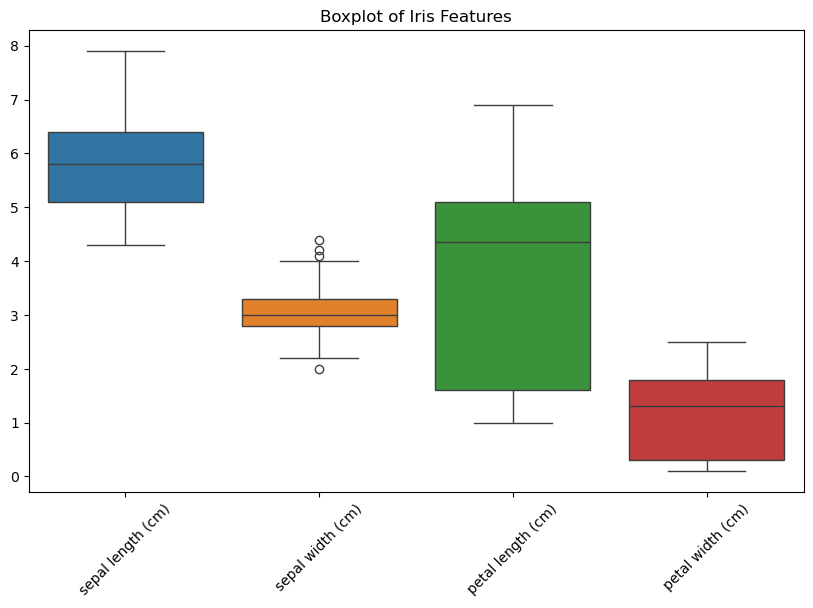

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=data.drop(columns="species"))

plt.title("Boxplot of Iris Features")
plt.xticks(rotation=45)
plt.show()

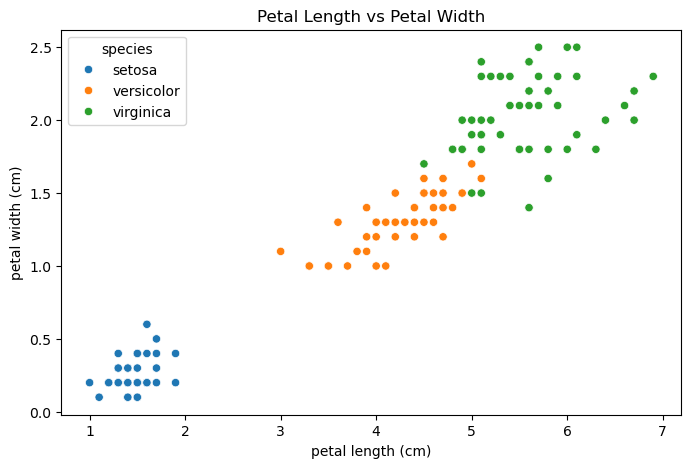

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species"
)

plt.title("Petal Length vs Petal Width")
plt.show()

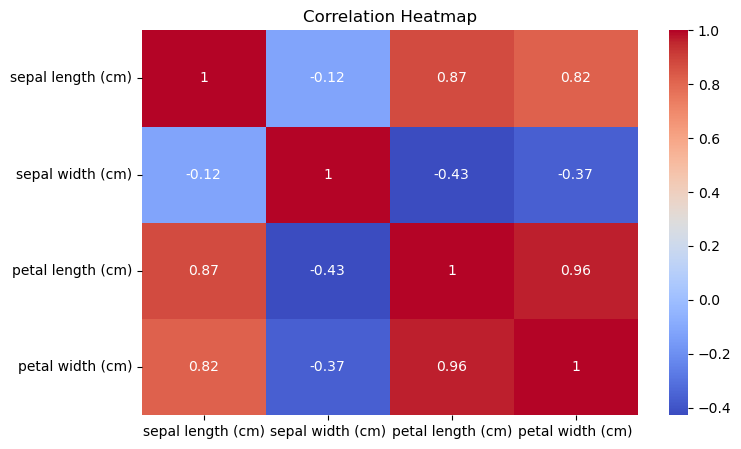

In [15]:
# Calculate correlation
corr = data.drop(columns="species").corr()

# Create heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

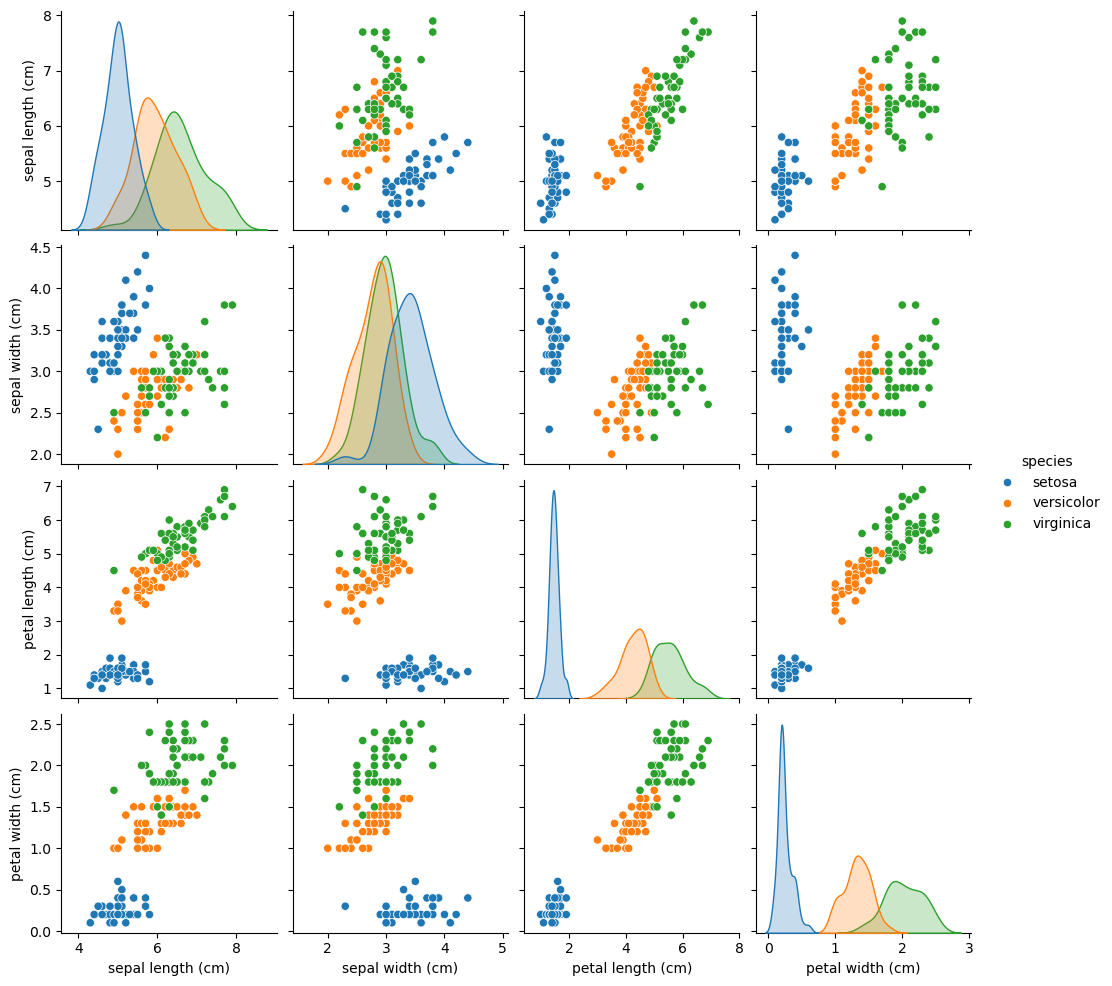

In [16]:
sns.pairplot(data, hue="species")

plt.show()

In [17]:
# Input features
X = data.drop(columns=["species"])

# Target variable
y = data["species"]

In [18]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget:")
print(y.head())

X shape: (150, 4)
y shape: (150,)

Input features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [20]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
model = LogisticRegression(max_iter=200)

In [24]:
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [25]:
# Make predictions
y_pred = model.predict(X_test)

# Display predictions
print(y_pred)

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [26]:
y_pred = model.predict(X_test)

In [27]:
print(y_pred)

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [28]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head(10))

       Actual   Predicted
0      setosa      setosa
1   virginica   virginica
2  versicolor  versicolor
3  versicolor  versicolor
4      setosa      setosa
5  versicolor  versicolor
6      setosa      setosa
7      setosa      setosa
8   virginica   virginica
9  versicolor  versicolor


In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 96.66666666666667 %


In [31]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


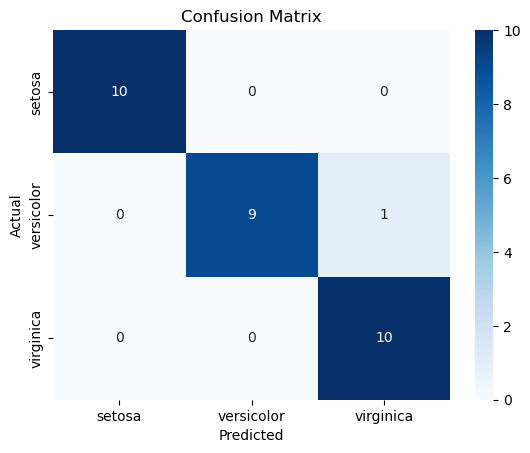

In [32]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [33]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [34]:
import pickle

with open("iris_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [35]:
import pickle

with open("iris_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [36]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = loaded_model.predict(new_flower)

print("Predicted Species:", prediction[0])

Predicted Species: setosa


C:\Users\syamb\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [37]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

prediction = loaded_model.predict(new_flower)

print("Predicted Species:", prediction[0])

Predicted Species: setosa


In [38]:
new_flowers = pd.DataFrame(
    [
        [5.1, 3.5, 1.4, 0.2],
        [6.0, 2.9, 4.5, 1.5],
        [6.5, 3.0, 5.8, 2.2]
    ],
    columns=X.columns
)

predictions = loaded_model.predict(new_flowers)

print("Predicted Species:")
print(predictions)

Predicted Species:
['setosa' 'versicolor' 'virginica']


In [39]:
print("Final Model: Logistic Regression")
print("Accuracy:", accuracy * 100, "%")
print("Model saved as: iris_model.pkl")

Final Model: Logistic Regression
Accuracy: 96.66666666666667 %
Model saved as: iris_model.pkl
